## <span style="color:purple"> Graph Time Series Plots Stacking Each Season </span>

<span style="color:purple"> These graphs will plot series data by day of the year, and then each season will be stacked on top of one another. The purpose of this is to visually inspect the variation in seasonality year-to-year, providing a basis to investigate interannual changes. </span>

### <span style="color:purple"> Plotting function </span>

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from FilterFunctions import lowpass_filter

# Global colour mapping for years
year_colours = {
    2001: "tab:blue",   2002: "tab:orange", 2003: "tab:green",
    2004: "tab:red",    2005: "tab:purple", 2006: "tab:brown",
    2007: "tab:pink",   2008: "tab:olive",  2009: "tab:cyan",
    2010: "darkblue",   2011: "crimson",    2012: "teal",
    2013: "goldenrod",
}

# Linestyle per position so you can distinguish cats
position_styles = {0: "-", 1: "--", 2: ":"}

seasons = {
    "Dec–Feb": [12, 1, 2],
    "Mar–May": [3, 4, 5],
    "Jun–Aug": [6, 7, 8],
    "Sep–Nov": [9, 10, 11],
}

def plot_seasonal_borehole(df, borehole, ylim_temp=None, ylim_sal=None, cutoff_period=720, sampling_interval=0.5, max_gap_hours=0):
    # Get cats sorted by median pressure (upper first)
    bh_data = df[df["borehole"] == borehole].copy()
    median_p = bh_data.groupby("cat")["pressure"].median().sort_values()
    cats = median_p.index.tolist()

    fig, axes = plt.subplots(2, 4, figsize=(24, 8), sharey="row")

    for col, (season_name, months) in enumerate(seasons.items()):
        axT = axes[0, col]
        axS = axes[1, col]

        for cat_idx, cat in enumerate(cats):
            mask = (bh_data["cat"] == cat) & (bh_data["time"].dt.month.isin(months))
            sub = bh_data[mask].copy()

            if sub.empty:
                continue

            sub["doy"] = sub["time"].dt.dayofyear + sub["time"].dt.hour / 24 + sub["time"].dt.minute / 1440
            sub["year"] = sub["time"].dt.year

            # For Dec-Feb, shift December DOY so it lines up before Jan
            if 12 in months:
                sub.loc[sub["time"].dt.month == 12, "doy"] -= 365

            years = sorted(sub["year"].unique())
            linestyle = position_styles.get(cat_idx, "-")

            # Plot individual years
            for year in years:
                yr_data = sub[sub["year"] == year]
                colour = year_colours.get(year, "grey")
                axT.plot(yr_data["doy"], yr_data["in_situ_temperature_smooth"], lw=0.6,
                         color=colour, alpha=0.3, linestyle=linestyle, label="_")
                axS.plot(yr_data["doy"], yr_data["practical_salinity_smooth"], lw=0.6,
                         color=colour, alpha=0.3, linestyle=linestyle, label="_")

            # Compute and plot median
            sub["doy_bin"] = (sub["doy"] * 48).round() / 48
            temp_median_raw = sub.groupby("doy_bin")["in_situ_temperature"].agg("median")
            sal_median_raw = sub.groupby("doy_bin")["practical_salinity"].agg("median")

            doy_index = temp_median_raw.index
            temp_median_smooth = lowpass_filter(temp_median_raw.values,
                                                cutoff_period=cutoff_period,
                                                sampling_interval=sampling_interval,
                                                max_gap_hours=max_gap_hours)
            sal_median_smooth = lowpass_filter(sal_median_raw.values,
                                              cutoff_period=cutoff_period,
                                              sampling_interval=sampling_interval,
                                              max_gap_hours=max_gap_hours)

            axT.plot(doy_index, temp_median_smooth, lw=2, color="black",
                     linestyle=linestyle, label=f"cat{cat}" if col == 0 else "_")
            axS.plot(doy_index, sal_median_smooth, lw=2, color="black",
                     linestyle=linestyle, label=f"cat{cat}" if col == 0 else "_")

        axT.set_title(season_name)
        axT.grid(True)
        axS.grid(True)
        axS.set_xlabel("Day of Year")

        if ylim_temp is not None: axT.set_ylim(*ylim_temp)
        if ylim_sal is not None: axS.set_ylim(*ylim_sal)

    axes[0, 0].set_ylabel("In Situ Temperature (°C)")
    axes[1, 0].set_ylabel("Practical Salinity (PSS78)")

    # Legend: cats (from median lines) + years
    cat_handles = axes[0, 0].get_legend_handles_labels()
    year_handles = [plt.Line2D([0], [0], color=year_colours[yr], lw=0.8, label=str(yr))
                    for yr in sorted(year_colours.keys())]
    axes[0, 0].legend(fontsize=7, ncols=2)

    fig.suptitle(f"{borehole} — Seasonal Temperature & Salinity", fontsize=14, y=1.02)
    plt.tight_layout()
    plt.show()

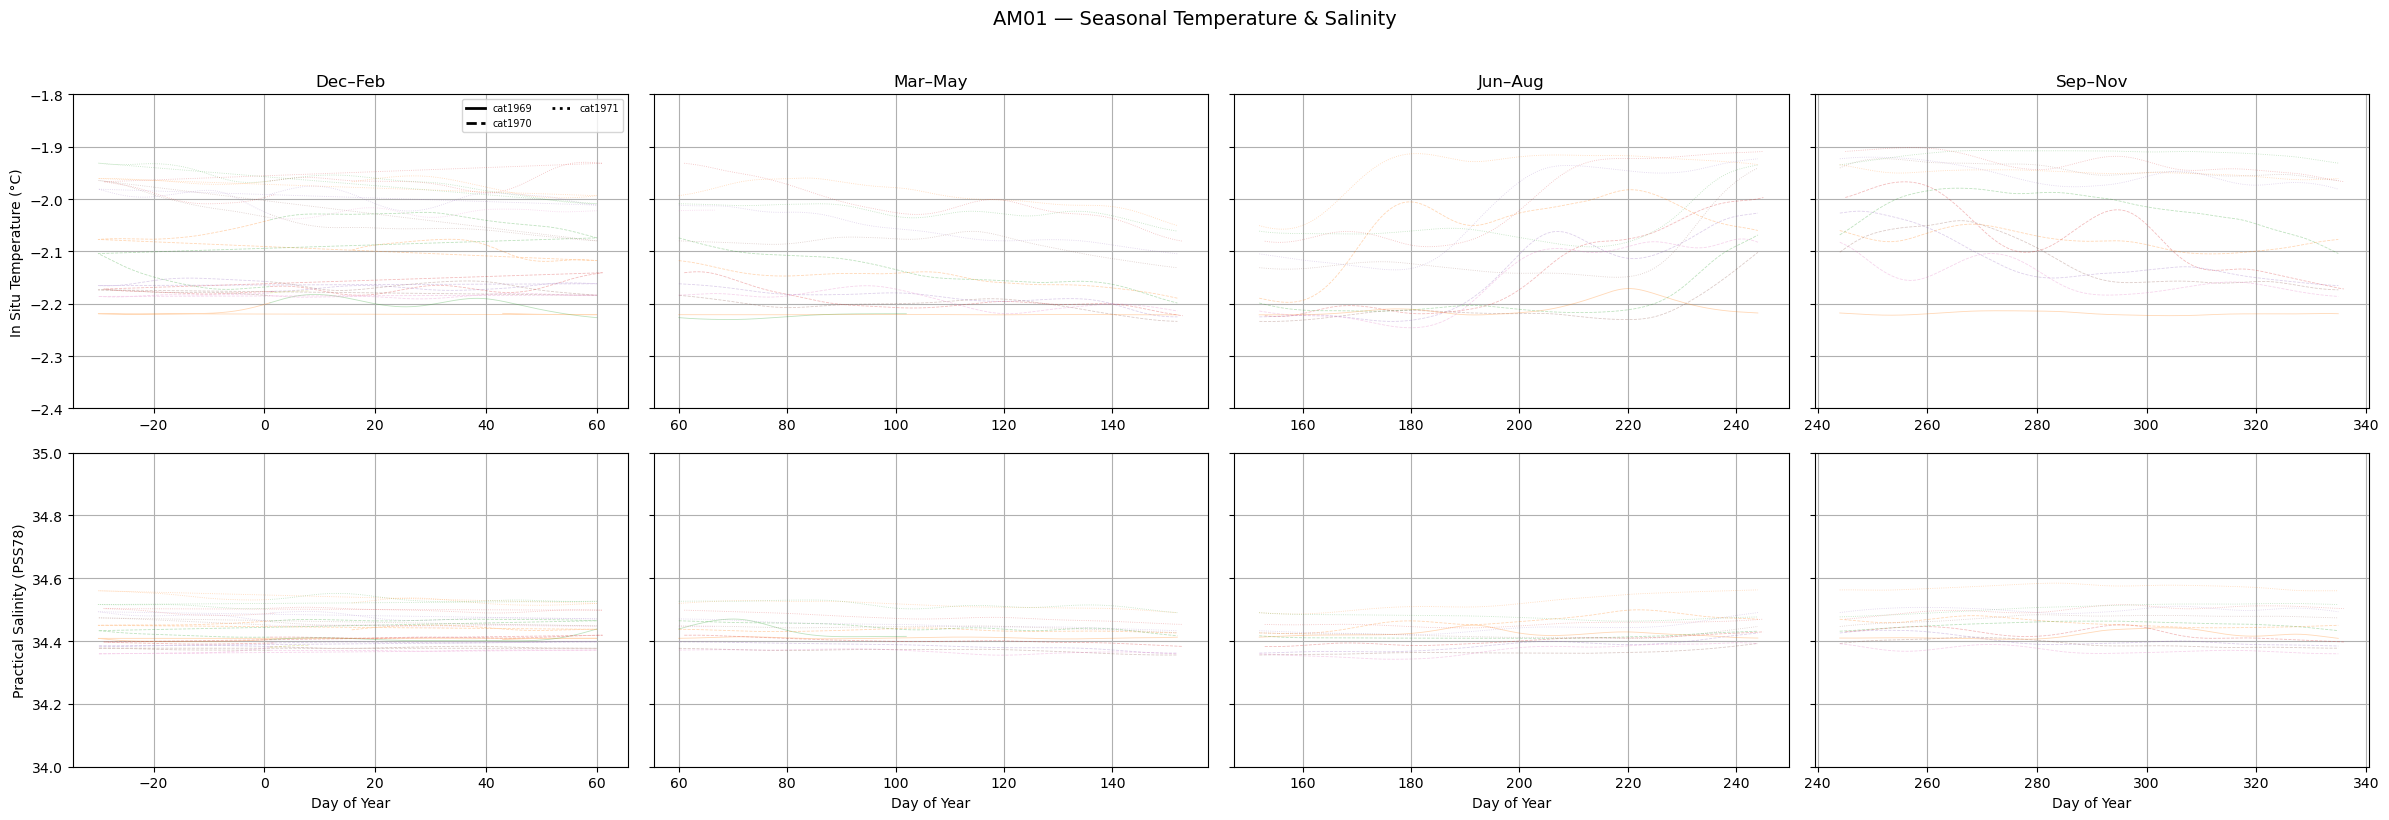

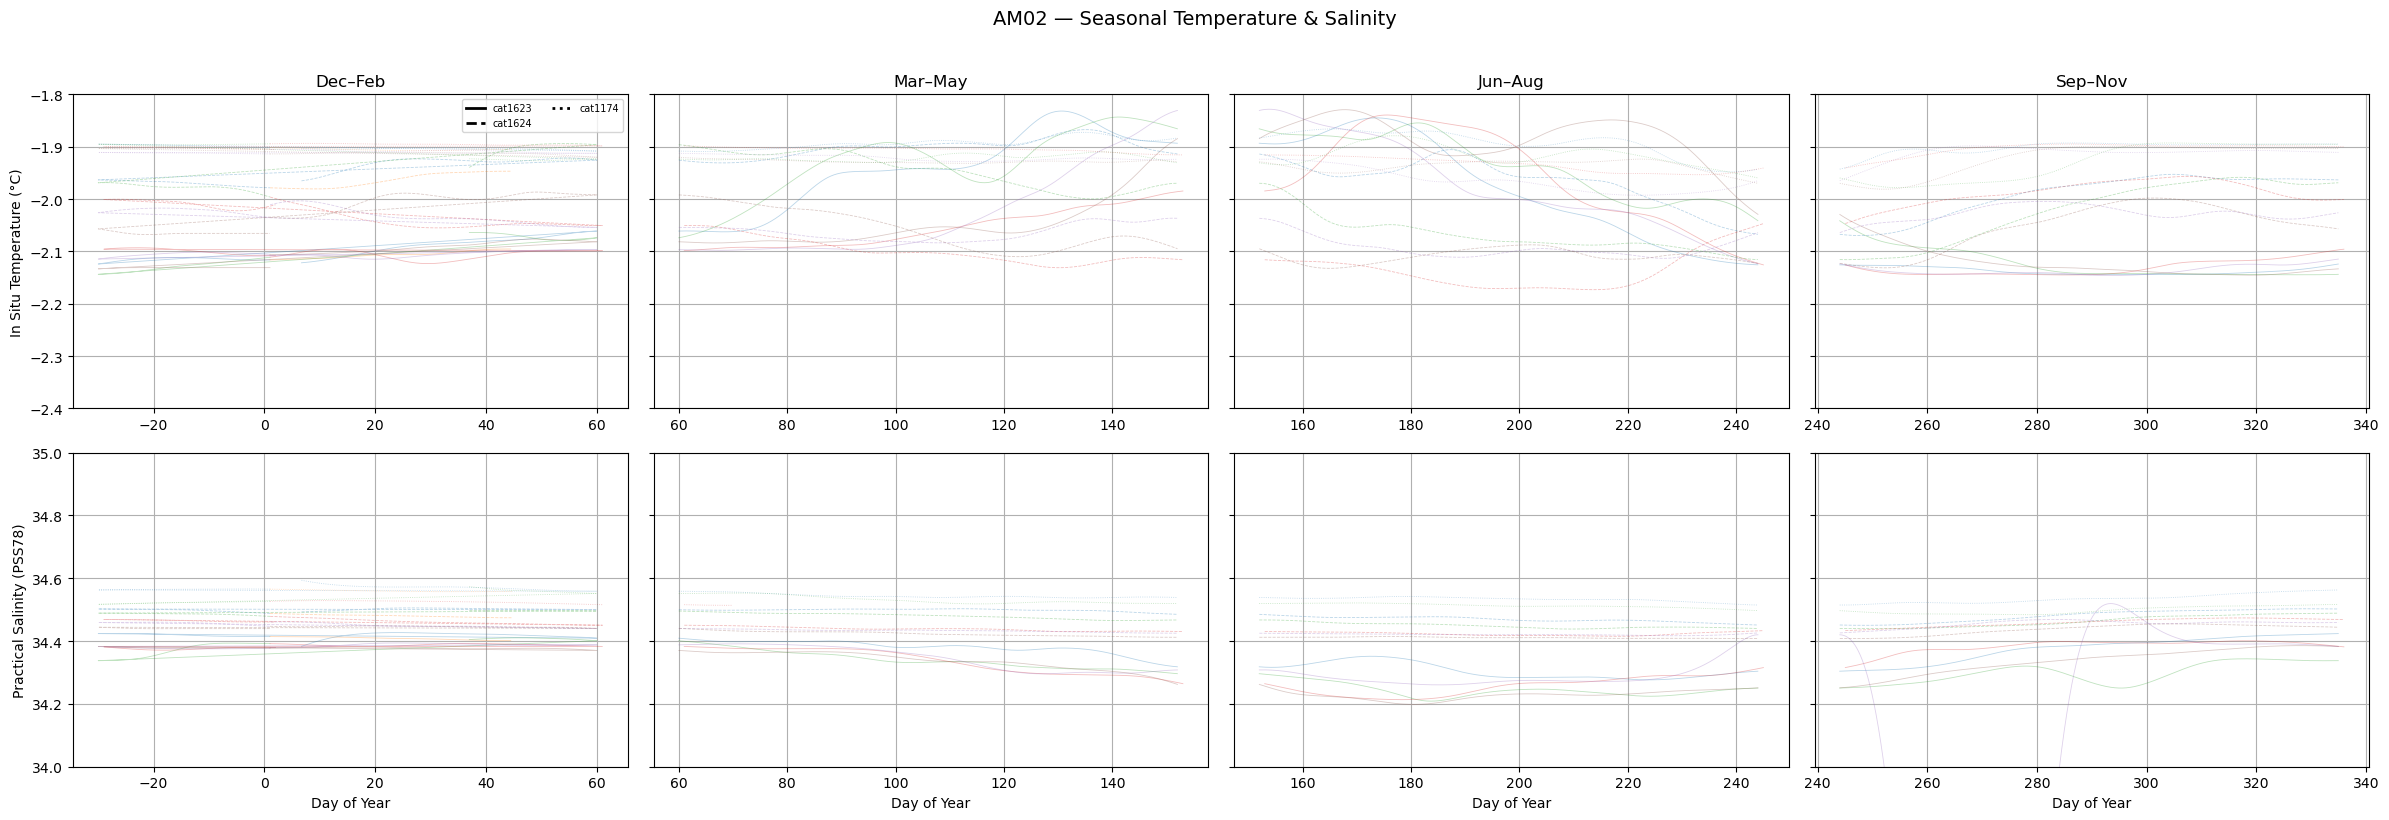

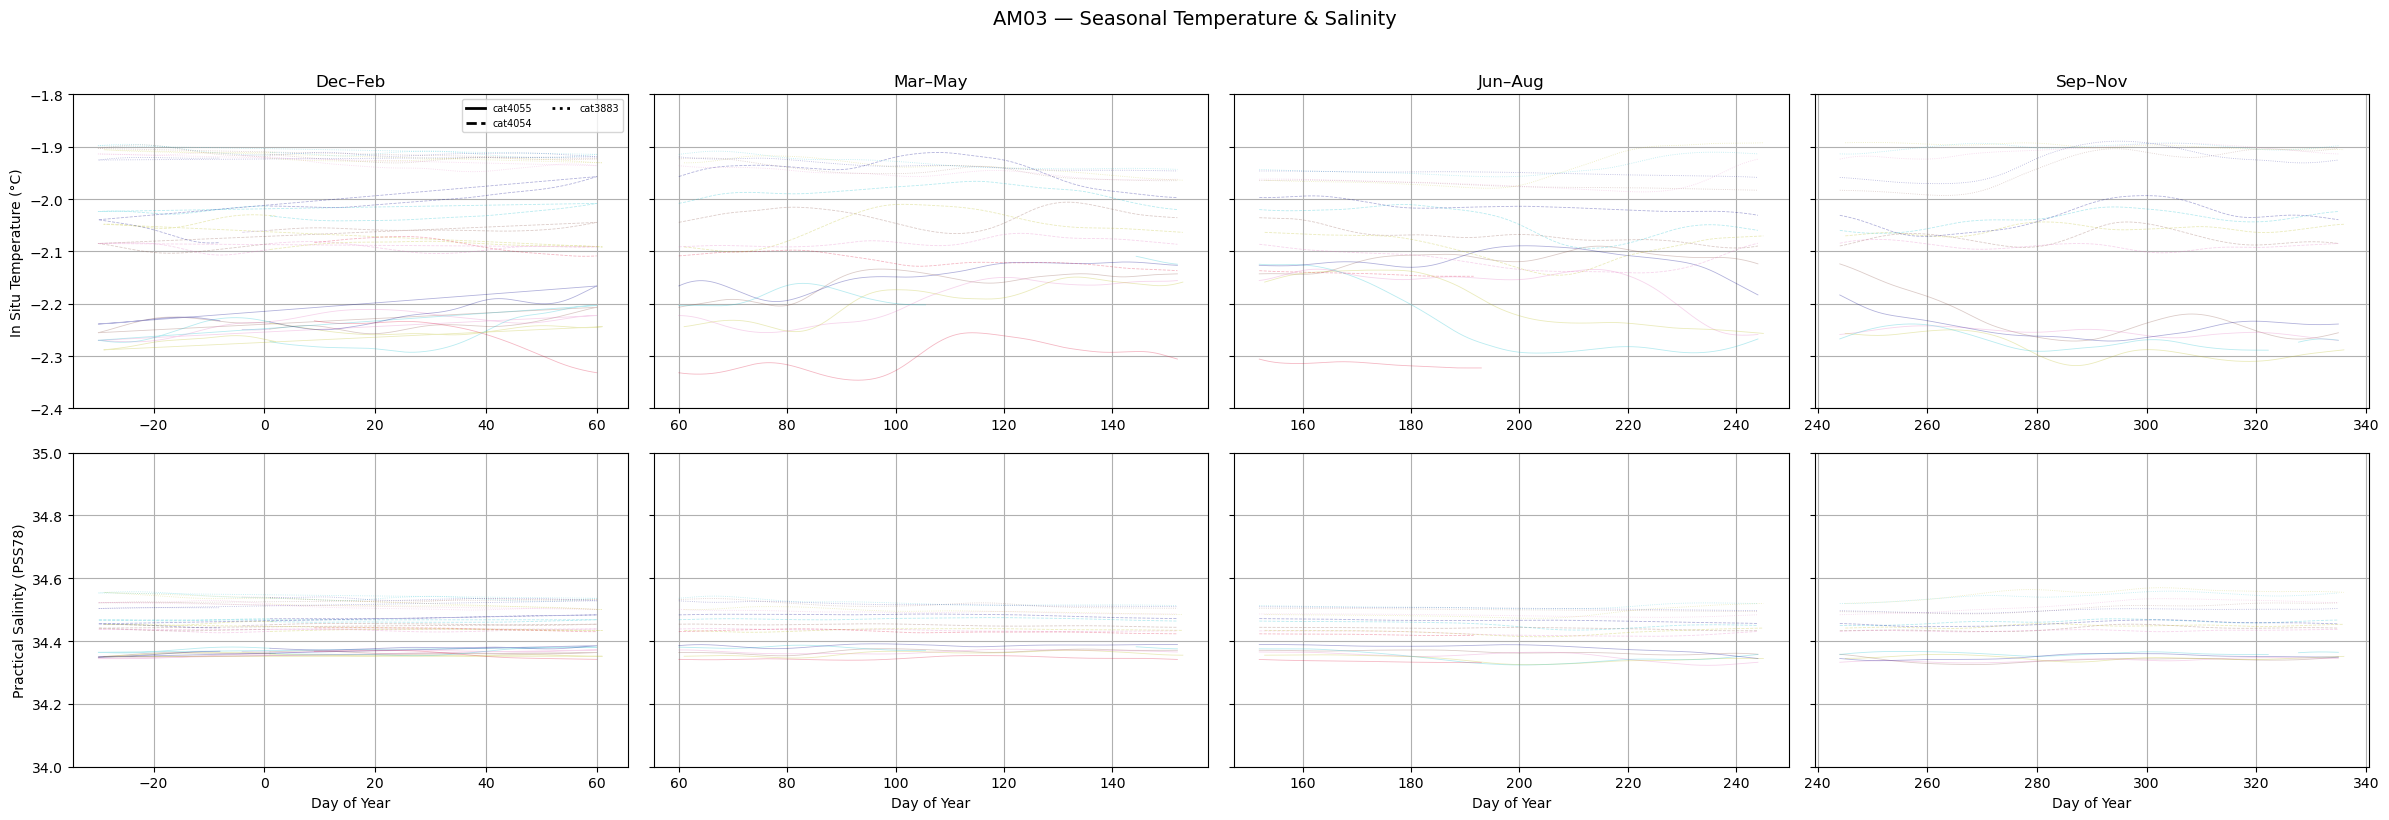

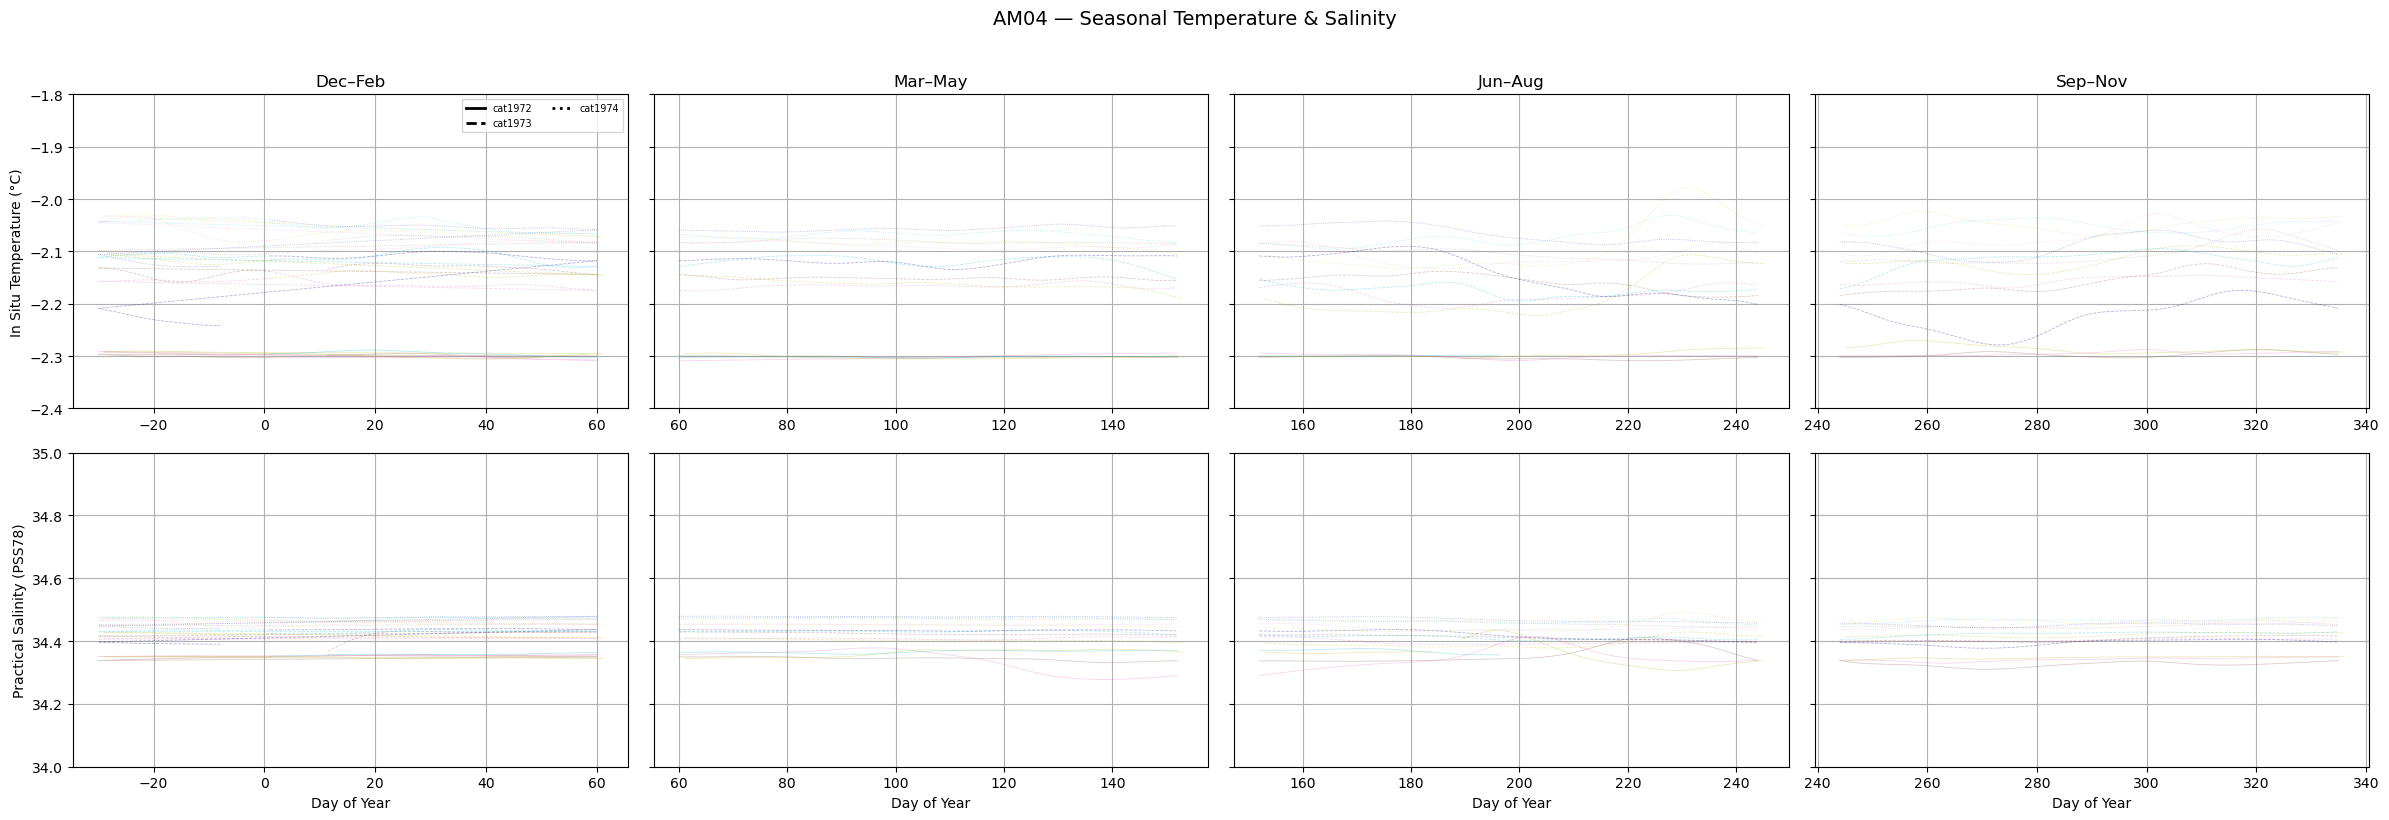

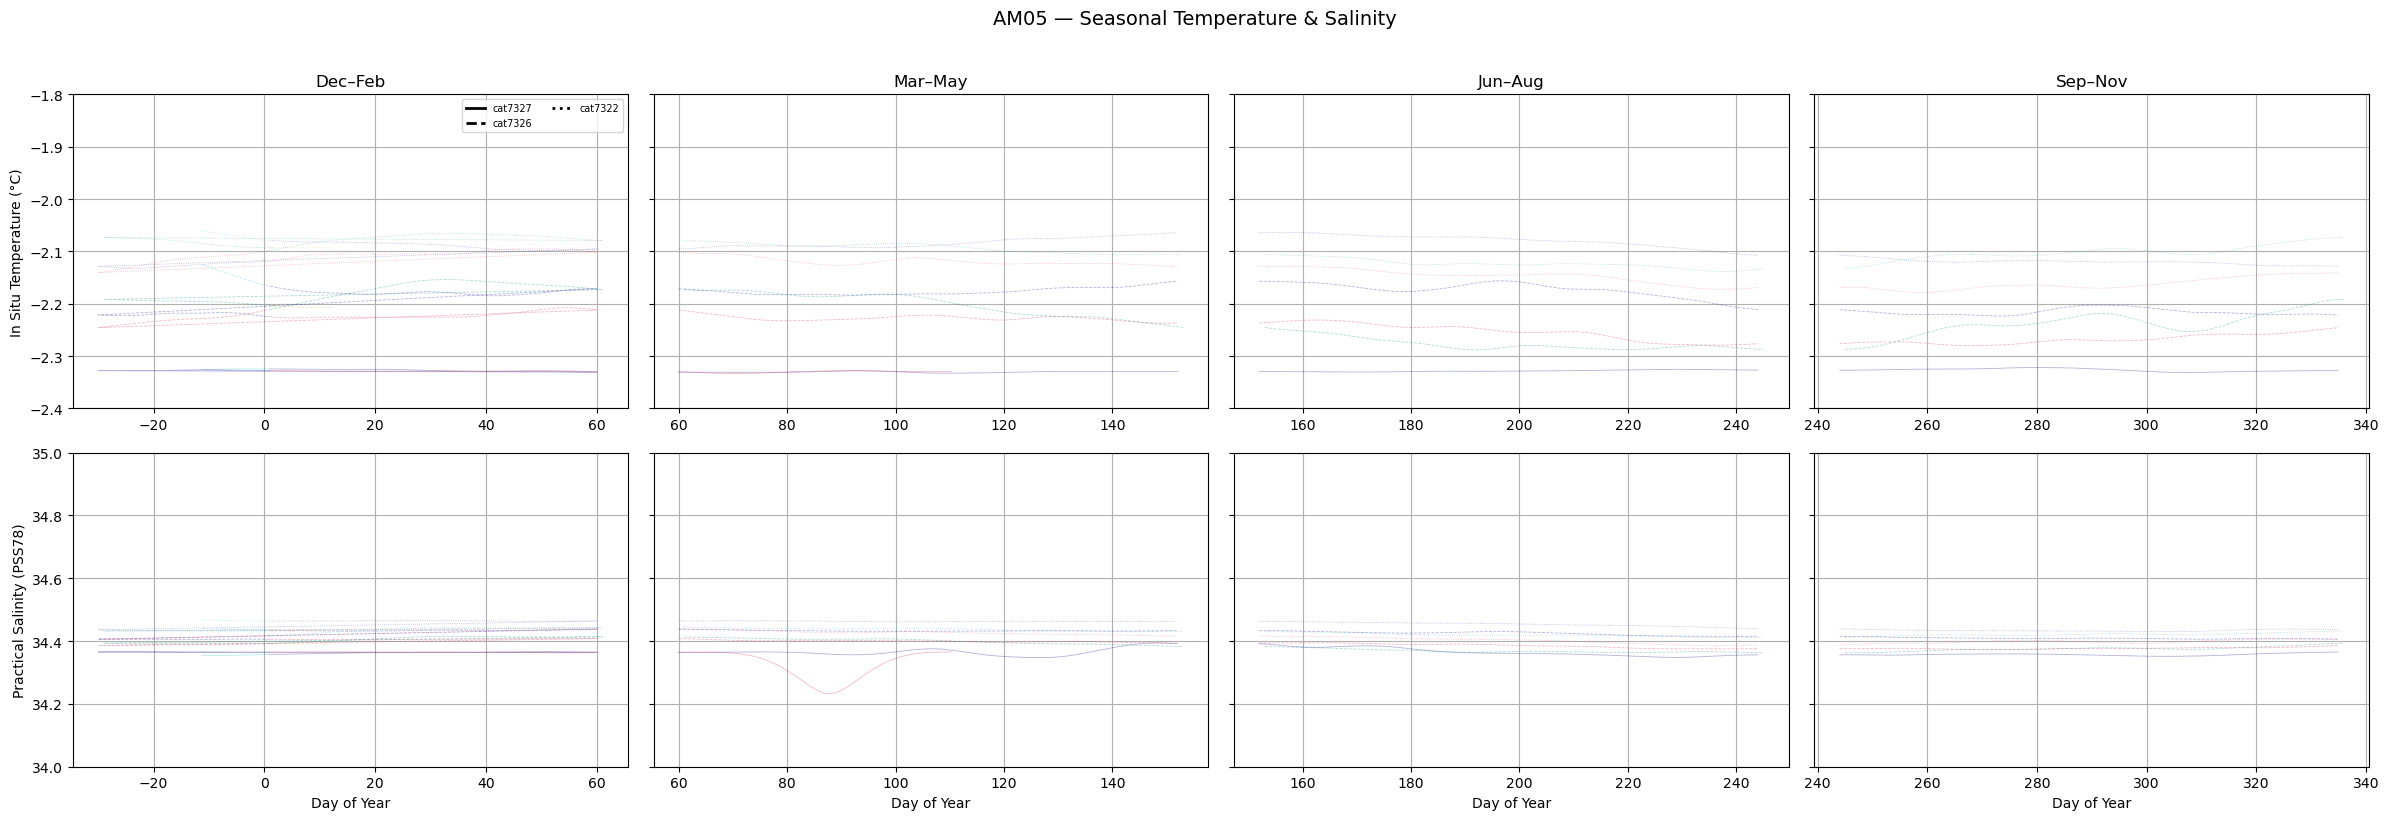

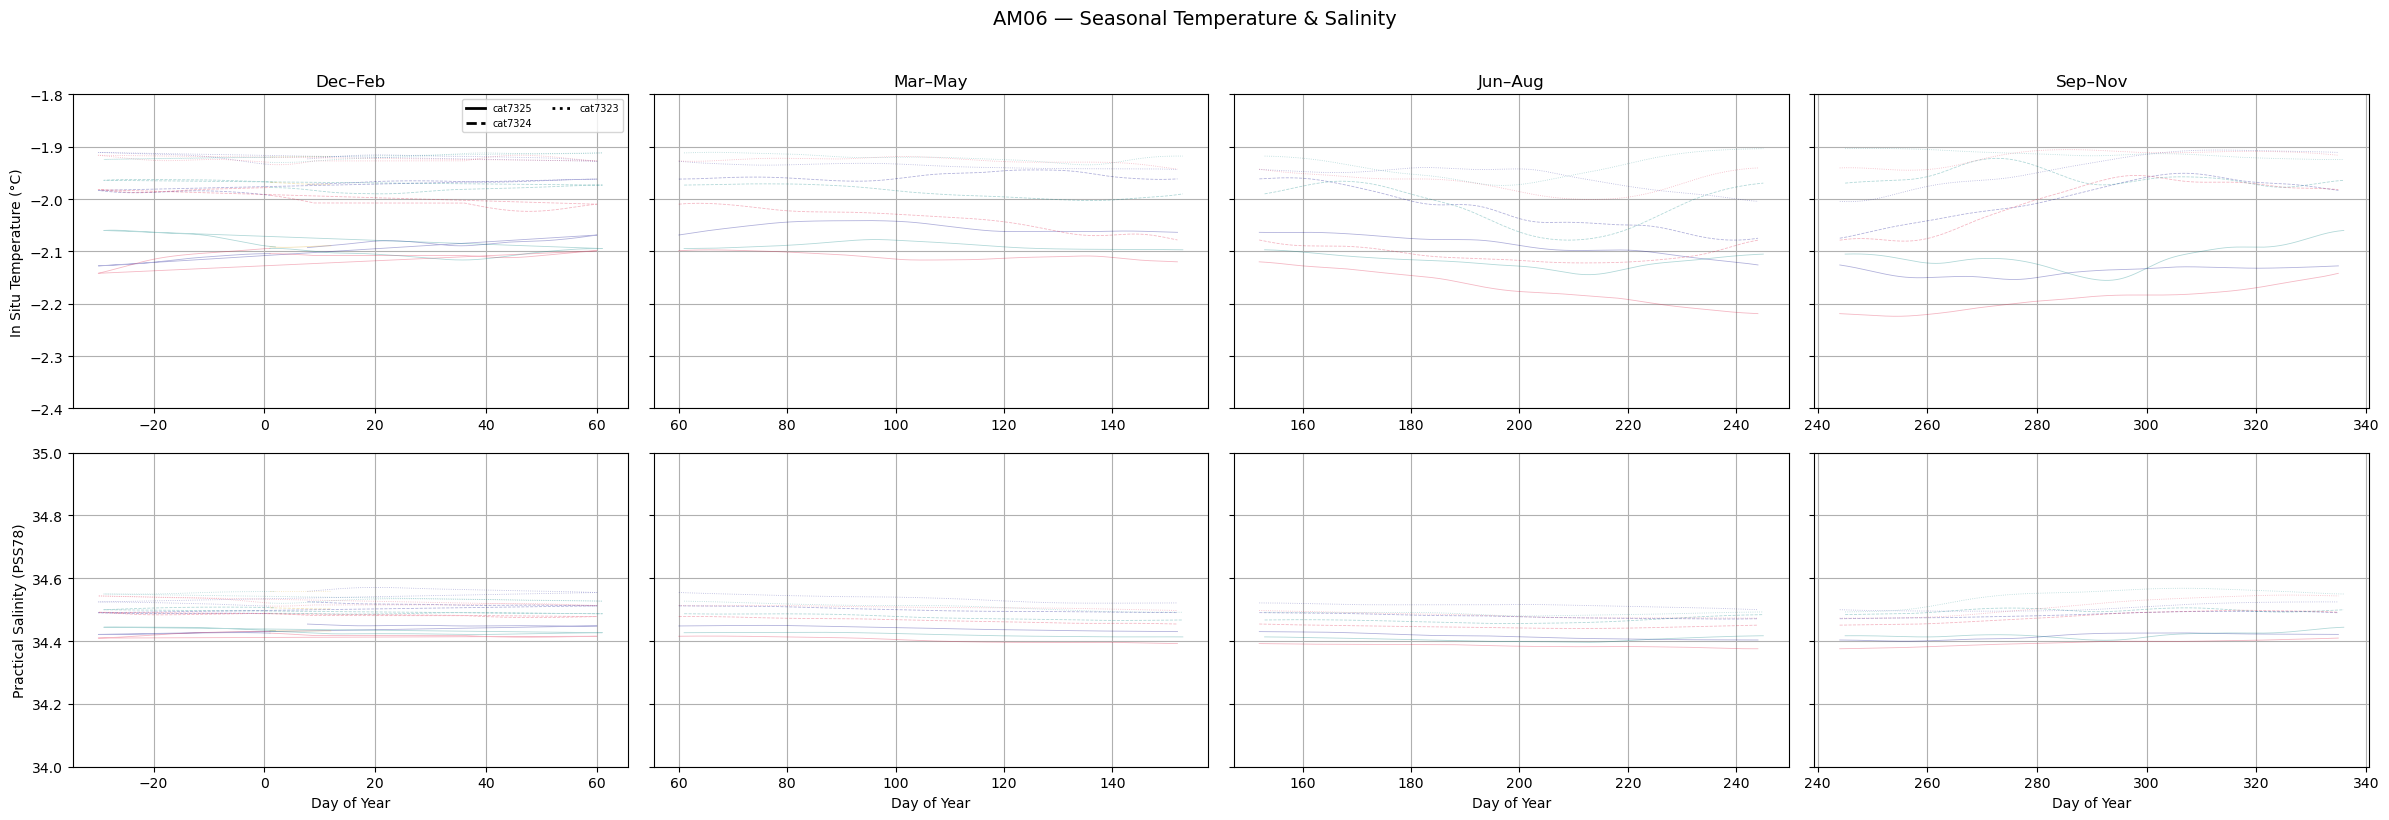

In [2]:
from FilterFunctions import apply_lowpass_filter, lowpass_filter

df = pd.read_parquet("../data/proc/03_pressure_handled.parquet")

cutoff_period_days = 30
interpolate_days = 7
df_filtered = apply_lowpass_filter(df, cutoff_period=cutoff_period_days*24,
                                    sampling_interval=0.5,
                                    max_gap_hours=interpolate_days*24)

for borehole in sorted(df_filtered["borehole"].unique()):
    plot_seasonal_borehole(df_filtered, borehole, (-2.4, -1.8), (34, 35),
                           cutoff_period=cutoff_period_days*24,
                           sampling_interval=0.5,
                           max_gap_hours=interpolate_days*24)